__aims:__

Identify cell types through combining our data with a reference dataset.

__minor changes:__
- I do not exclude female this time! So I can annotate cell types for all samples at the same time.

__tasks:__

- [x] Gather data for nucleus-accumbens (NAs) subtypes as reference
- [x] Train the AE model on reference data for cell type prediction on our data
- [ ] Redo our cell type identification using these predictions
___
- I asked this https://github.com/theislab/scarches/issues/185
- `SCANVI` – https://docs.scarches.org/en/latest/scanvi_surgery_pipeline.html
<!-- https://scarchest.readthedocs.io/en/latest/scanvi_surgery_pipeline.html
     -->
    <!-- https://docs.scvi-tools.org/en/stable/tutorials/notebooks/harmonization.html
    `scvi`
    https://docs.scvi-tools.org/en/stable/tutorials/notebooks/api_overview.html#Loading-and-preparing-data
    > Finally, we perform feature selection, to reduce the number of features (genes in this case) used as input to the scvi-tools model. For best practices of how/when to perform feature selection, please refer to the model-specific tutorial. For scVI, we recommend anywhere from 1,000 to 10,000 HVGs, but it will be context-dependent.
-->



___
https://docs.scvi-tools.org/

### Semi-supervised surgery pipeline with SCANVI

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import scarches as sca
import torch
import scvi
import scez

from scarches.dataset.trvae.data_handling import remove_sparsity
from venn import venn

torch.set_printoptions(precision=3, sci_mode=False, edgeitems=7)


 captum (see https://github.com/pytorch/captum).


scanpy==1.9.6 anndata==0.10.7 umap==0.5.5 numpy==1.26.4 scipy==1.13.0 pandas==1.5.3 scikit-learn==1.4.2 statsmodels==0.14.2 igraph==0.11.5 pynndescent==0.5.12


In [2]:
from scez_old import clustering

scanpy==1.9.6 anndata==0.10.7 umap==0.5.5 numpy==1.26.4 scipy==1.13.0 pandas==1.5.3 scikit-learn==1.4.2 statsmodels==0.14.2 igraph==0.11.5 pynndescent==0.5.12


### Download Dataset and split into reference dataset and query dataset

#### NAs-subtypes

##### Download data

In [ ]:
# !wget https://ftp.ncbi.nlm.nih.gov/geo/series/GSE118nnn/GSE118020/suppl/GSE118020_expression_matrix.csv.gz

--2023-03-27 15:14:46--  https://ftp.ncbi.nlm.nih.gov/geo/series/GSE118nnn/GSE118020/suppl/GSE118020_expression_matrix.csv.gz
Resolving ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)... 130.14.250.7, 130.14.250.10
Connecting to ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)|130.14.250.7|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 96453357 (92M) [application/x-gzip]
Saving to: ‘GSE118020_expression_matrix.csv.gz’

GSE118020_expressio 100%[===================>]  91.98M  2.95MB/s    in 30s     

2023-03-27 15:15:17 (3.03 MB/s) - ‘GSE118020_expression_matrix.csv.gz’ saved [96453357/96453357]



In [5]:
# !wget https://ftp.ncbi.nlm.nih.gov/geo/series/GSE118nnn/GSE118020/suppl/GSE118020_meta_data.csv.gz

--2023-03-27 15:15:17--  https://ftp.ncbi.nlm.nih.gov/geo/series/GSE118nnn/GSE118020/suppl/GSE118020_meta_data.csv.gz
Resolving ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)... 130.14.250.10, 130.14.250.7
Connecting to ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)|130.14.250.10|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1139724 (1.1M) [application/x-gzip]
Saving to: ‘GSE118020_meta_data.csv.gz’

GSE118020_meta_data 100%[===================>]   1.09M  2.32MB/s    in 0.5s    

2023-03-27 15:15:18 (2.32 MB/s) - ‘GSE118020_meta_data.csv.gz’ saved [1139724/1139724]



In [6]:
# mkdir GSE118020

In [9]:
# mv -v GSE118020_* GSE118020/

##### make `annData`

In [8]:
# counts = pd.read_csv('GSE118020/GSE118020_expression_matrix.csv.gz',index_col=0).T

In [7]:
# meta = pd.read_csv('GSE118020/GSE118020_meta_data.csv.gz',index_col=0)

https://github.com/theislab/scarches/issues/181#issuecomment-1481792842

In [ ]:
# adata = ad.AnnData(
#     X = counts,
#     obs = meta,
#     dtype='float32'
# )

In [ ]:
# adata.write_h5ad('GSE118020/GSE118020_adata.h5ad.gz')

#### Load, combine, and prepare `adata`

In [3]:
rdata = sc.read_h5ad('GSE118020/GSE118020_adata.h5ad.gz')

rdata.obs['dataset'] = 'source_data'

In [17]:
scez.pp.normalization(rdata, final_layer='log1p_norm')

In [19]:
rdata

AnnData object with n_obs × n_vars = 47576 × 26145
    obs: 'nGene', 'nUMI', 'orig.ident', 'percent.mito', 'Sample', 'tree.ident', 'CellType', 'L2_Clustering', 'dataset'
    uns: 'pca', 'neighbors', 'umap', 'CellType_colors', 'L2_Clustering_colors', 'rank_genes_groups'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'raw_counts', 'log1p_norm', 'scaled'
    obsp: 'distances', 'connectivities'

In [6]:
# sc.pp.highly_variable_genes(
#     rdata, min_mean=0.01, max_mean=10, min_disp=0.01,
# )

In [20]:
sc.pp.pca(rdata,n_comps=30)#,use_highly_variable=True, svd_solver='arpack')
sc.pp.neighbors(rdata)    # why can't we just work with the default neighbors?
#, use_rep=rep, n_neighbors=n_neighbor)

In [21]:
sc.tl.umap(rdata)#, min_dist=0.1, spread=1)

___

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:371: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:381: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


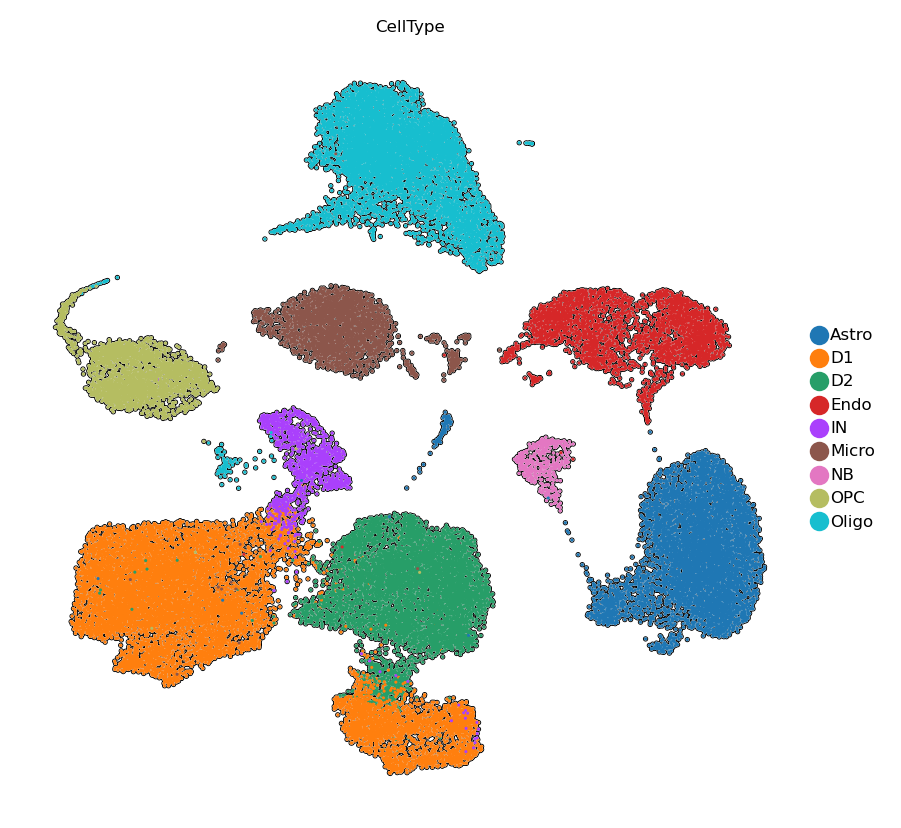

In [22]:
sc.pl.umap(
    rdata,
    color=['CellType'],
    # layer='scaled',
    cmap='Reds',
    frameon=False,
    alpha=1,
    size=5,
    add_outline=0.01
    # vmin=5,# vmax=1000,
    # save='all.pdf',
    # add_outline=.1
)

# !mv figures/umapall.pdf preprocessing/total_counts_mt_umap.pdf

In [16]:
sc.tl.rank_genes_groups(
    rdata, 'CellType', method='wilcoxon'
)

In [24]:
scez.utils.rank_genes_to_df(
    rdata, 
    n = 200
    # n = adata_neuron.var.shape[0]
).to_csv('GSE118020/ranked_NAc_atlas.csv')

___

In [4]:
results_file = 'preprocessing/adata-cleaned-v3.h5ad.gz'

adata0 = sc.read_h5ad(results_file)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Exclude female!?

In [5]:
adata0 = adata0[~adata0.obs.cond.str.contains('female')].copy()

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


___

In [6]:
adata = adata0.copy()

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [7]:
adata.var_names_make_unique()

adata.obs['dataset'] = 'target_data'

In [8]:
ol_genes = list(set(adata.var.index) & set(rdata.var.index))

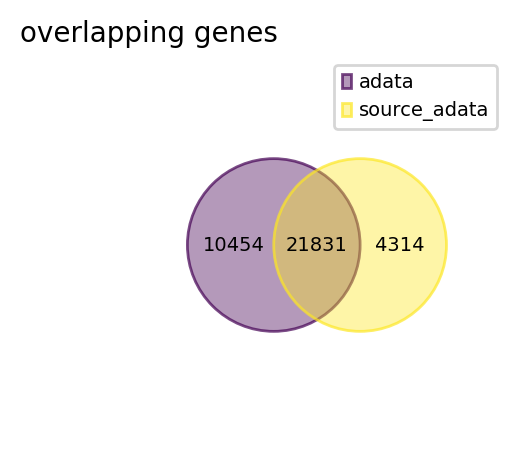

In [9]:
_, ax = plt.subplots(ncols=1, nrows=1, figsize=(12, 2.5))

venn({
    'adata':set(adata.var.index),
    'source_adata':set(rdata.var.index)
},ax=ax,fontsize=7)

plt.suptitle('overlapping genes')
plt.show()

In [10]:
cdata = sc.concat([
    adata[:,adata.var.index.isin(ol_genes)],
    rdata[:,rdata.var.index.isin(ol_genes)]
])

In [11]:
cdata = remove_sparsity(cdata)

In [12]:
cdata.obs.groupby('dataset').size()

dataset
source_data    47576
target_data    23801
dtype: int64

___

In [13]:
cdata

AnnData object with n_obs × n_vars = 71377 × 21831
    obs: 'dataset'

In [14]:
source_adata = cdata[cdata.obs['dataset'].eq('source_data')].copy()
target_adata = cdata[cdata.obs['dataset'].eq('target_data')].copy()

In [15]:
source_adata.obs = rdata.obs

In [16]:
target_adata.obs = adata.obs

In [17]:
target_adata.obs = target_adata.obs.rename(columns={'batch':'Sample'})

In [18]:
source_adata.obs.groupby('CellType').size()

CellType
Astro     7537
D1       12342
D2        7687
Endo      3516
IN        1330
Micro     3230
NB         483
OPC       3031
Oligo     8420
dtype: int64

In [19]:
target_adata.obs.groupby('cond').size()

cond
MDMA_acute_male     8963
MDMA_male           1322
Meth_male           3249
Saline_male        10267
dtype: int64

### Create SCANVI model and train it on fully labelled reference dataset

In [20]:
condition_key='Sample'
cell_type_key='CellType'

In [21]:
sca.models.SCVI.setup_anndata(source_adata, batch_key=condition_key, labels_key=cell_type_key)

In [22]:
vae = sca.models.SCVI(
    source_adata,
    n_layers=2,
    encode_covariates=True,
    deeply_inject_covariates=False,
    use_layer_norm="both",
    use_batch_norm="none",
)

In [23]:
vae.train()

INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: IPU available: False, using: 0 IPUs
INFO:lightning.pytorch.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:441: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.


Epoch 168/168: 100%|██████████| 168/168 [1:17:44<00:00, 28.49s/it, v_num=1, train_loss_step=5.37e+3, train_loss_epoch=5.18e+3]

INFO: `Trainer.fit` stopped: `max_epochs=168` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=168` reached.


Epoch 168/168: 100%|██████████| 168/168 [1:17:44<00:00, 27.76s/it, v_num=1, train_loss_step=5.37e+3, train_loss_epoch=5.18e+3]


In [25]:
scanvae = sca.models.SCANVI.from_scvi_model(vae, unlabeled_category = "Unknown")

In [26]:
print("Labelled Indices: ", len(scanvae._labeled_indices))
print("Unlabelled Indices: ", len(scanvae._unlabeled_indices))

Labelled Indices:  47576
Unlabelled Indices:  0


In [27]:
scanvae.train(max_epochs=200)

INFO     Training for 20 epochs.                                                                                   


INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: IPU available: False, using: 0 IPUs
INFO:lightning.pytorch.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:441: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.


Epoch 20/20: 100%|██████████| 20/20 [10:24<00:00, 28.03s/it, v_num=1, train_loss_step=5.29e+3, train_loss_epoch=5.18e+3]

INFO: `Trainer.fit` stopped: `max_epochs=20` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=20` reached.


Epoch 20/20: 100%|██████████| 20/20 [10:24<00:00, 31.21s/it, v_num=1, train_loss_step=5.29e+3, train_loss_epoch=5.18e+3]


### Create anndata file of latent representation and compute UMAP


In [28]:
reference_latent = sc.AnnData(scanvae.get_latent_representation())
reference_latent.obs["cell_type"] = source_adata.obs[cell_type_key].tolist()
reference_latent.obs["batch"] = source_adata.obs[condition_key].tolist()

In [29]:
reference_latent

AnnData object with n_obs × n_vars = 47576 × 10
    obs: 'cell_type', 'batch'

In [30]:
sc.pp.neighbors(reference_latent, n_neighbors=8)

In [31]:
sc.tl.leiden(reference_latent)
sc.tl.umap(reference_latent)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


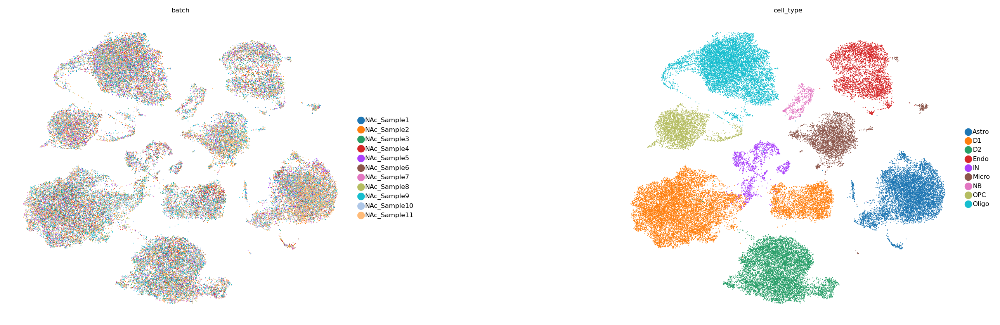

In [32]:
sc.pl.umap(reference_latent,
           color=['batch', 'cell_type'],
           frameon=False,
           wspace=0.6,
           )

In [35]:
reference_latent.obs['predictions'] = scanvae.predict()

In [36]:
print("Acc: {}".format(np.mean(reference_latent.obs.predictions == reference_latent.obs.cell_type)))

Acc: 0.9989490499411467


#### Save model

In [37]:
!mkdir -p scanvi_models

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/pty.py:85: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


In [38]:
# ref_path = 'scanvi_models/09_05_2023_ref_model/'
ref_path = 'scanvi_models/05_19_2024_ref_model/'

scanvae.save(ref_path, overwrite=True)

In [39]:
ls -lh scanvi_models/

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/pty.py:85: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


total 0
drwxrwxr-x. 2 aarab aarab 30 May 19 13:37 05_19_2024_ref_model/
drwxrwxr-x. 2 aarab aarab 30 May 19 13:52 05_19_2024_surgery_model/
drwxrwxr-x. 2 aarab aarab 30 May  9  2023 09_05_2023_ref_model/


### Perform surgery on reference model and train on query dataset without cell type labels

In [40]:
model = sca.models.SCANVI.load_query_data(
    target_adata,
    ref_path,
    freeze_dropout = True,
)
model._unlabeled_indices = np.arange(target_adata.n_obs)
model._labeled_indices = []

INFO     File scanvi_models/05_19_2024_ref_model/model.pt already downloaded                                       


/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scvi/data/_manager.py:209: UserWarning: Missing labels key CellType. Filling in with unlabeled category Unknown.
  field_registry[_constants._STATE_REGISTRY_KEY] = field.transfer_field(


In [41]:
print("Labelled Indices: ", len(model._labeled_indices))
print("Unlabelled Indices: ", len(model._unlabeled_indices))

Labelled Indices:  0
Unlabelled Indices:  23801


In [42]:
model.train(
    max_epochs=200,
    plan_kwargs=dict(weight_decay=0.0),
    check_val_every_n_epoch=10,
)

INFO     Training for 100 epochs.                                                                                  


INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: IPU available: False, using: 0 IPUs
INFO:lightning.pytorch.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:441: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.


Epoch 10/100:   9%|▉         | 9/100 [01:15<12:35,  8.31s/it, v_num=1, train_loss_step=7.17e+3, train_loss_epoch=6.87e+3]

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:441: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.


Epoch 100/100: 100%|██████████| 100/100 [13:12<00:00,  7.82s/it, v_num=1, train_loss_step=6.48e+3, train_loss_epoch=6.8e+3]

INFO: `Trainer.fit` stopped: `max_epochs=100` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [13:12<00:00,  7.92s/it, v_num=1, train_loss_step=6.48e+3, train_loss_epoch=6.8e+3]


In [43]:
query_latent = sc.AnnData(model.get_latent_representation())
query_latent.obs['cell_type'] = target_adata.obs[cell_type_key].tolist()
query_latent.obs['batch'] = target_adata.obs[condition_key].tolist()

In [44]:
sc.pp.neighbors(query_latent)
sc.tl.leiden(query_latent)
sc.tl.umap(query_latent)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


<Figure size 500x500 with 0 Axes>

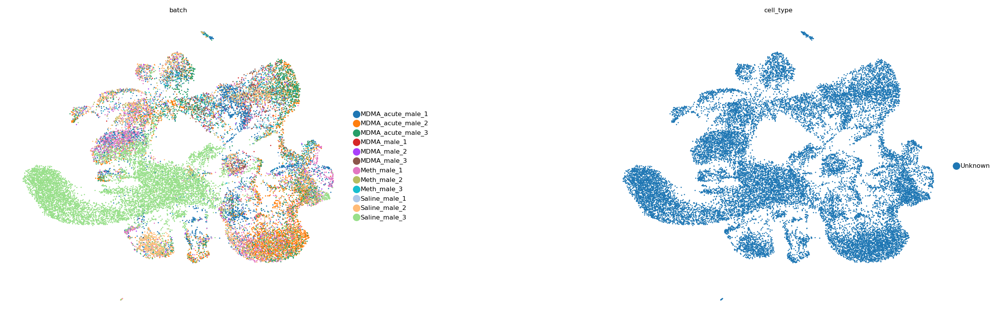

In [45]:
plt.figure()
sc.pl.umap(
    query_latent,
    color=["batch", "cell_type"],
    frameon=False,
    wspace=0.6,
)

### Save model

In [46]:
# surgery_path = 'scanvi_models/09_05_2023_surgery_model'
surgery_path = 'scanvi_models/05_19_2024_surgery_model'
model.save(surgery_path, overwrite=True)


### Get latent representation of reference + query dataset and compute UMAP

In [49]:
adata_full = source_adata.concatenate(target_adata)

In [50]:
condition_key

'Sample'

In [51]:
clustering(adata_full, res=0.3)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


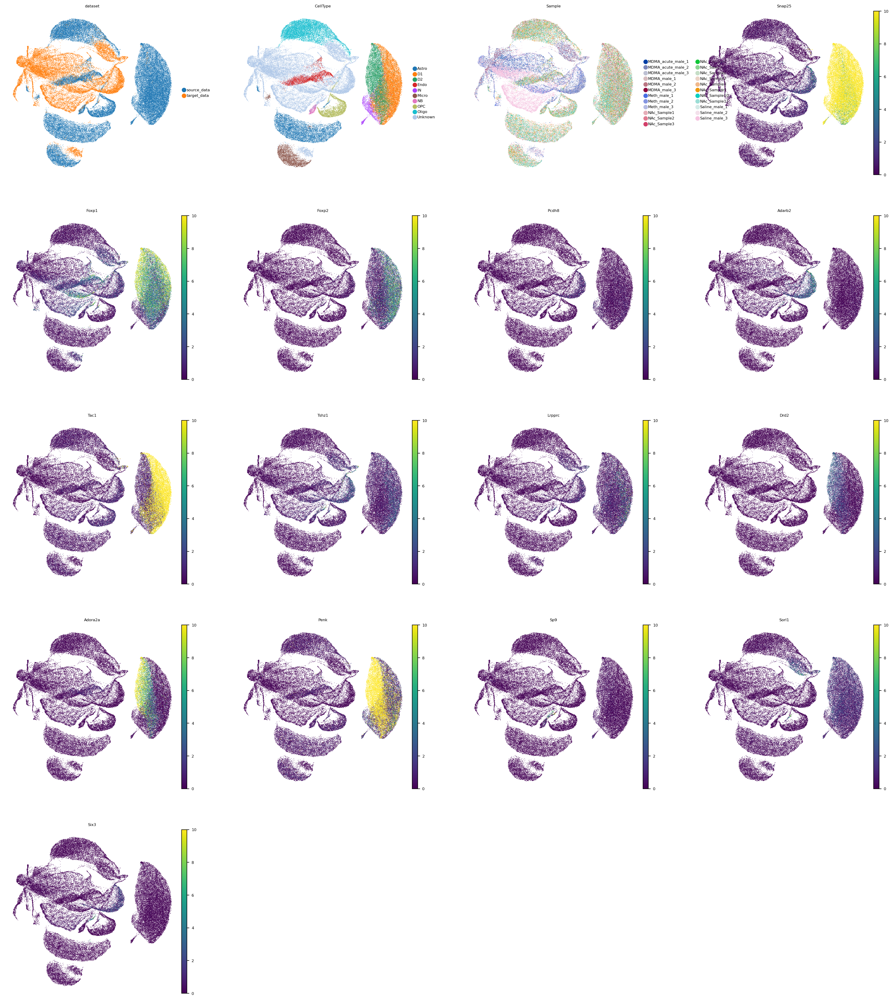

In [52]:
sc.pl.umap(
    adata_full,
    color=[
        "dataset", 
        "CellType",
        'Sample',    
        'Snap25',
        "Foxp1",
        "Foxp2",
        # "Camk4",
        "Pcdh8",
        # "Tacr1",
        "Adarb2",
        "Tac1",
        "Tshz1",
        "Lrpprc",
        # "Drd1a",
        "Drd2",
        "Adora2a",
        "Penk",
        "Sp9",
        "Sorl1",
        "Six3",
    
    ],
    frameon=False,
    vmax=10,
    wspace=0.2,
)

In [53]:
# adata_full.obs

In [54]:
full_latent = sc.AnnData(model.get_latent_representation(adata=adata_full))
full_latent.obs['cell_type'] = adata_full.obs[cell_type_key].tolist()
full_latent.obs['batch'] = adata_full.obs[condition_key].tolist()

INFO     Input AnnData not setup with scvi-tools. attempting to transfer AnnData setup                             


In [55]:
full_latent

AnnData object with n_obs × n_vars = 71377 × 10
    obs: 'cell_type', 'batch'

In [56]:
# sc.pp.neighbors(full_latent)
# sc.tl.leiden(full_latent)
# sc.tl.umap(full_latent)

In [57]:
clustering(full_latent, n_neighbor=15 ,n_comps=2, res=0.1)

In [58]:
sc.tl.umap(full_latent,min_dist=0.3)

In [59]:
full_latent

AnnData object with n_obs × n_vars = 71377 × 10
    obs: 'cell_type', 'batch', 'leiden'
    uns: 'pca', 'neighbors', 'umap', 'leiden'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [60]:
full_latent.obs['dataset'] = adata_full.obs['dataset'].to_list()

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


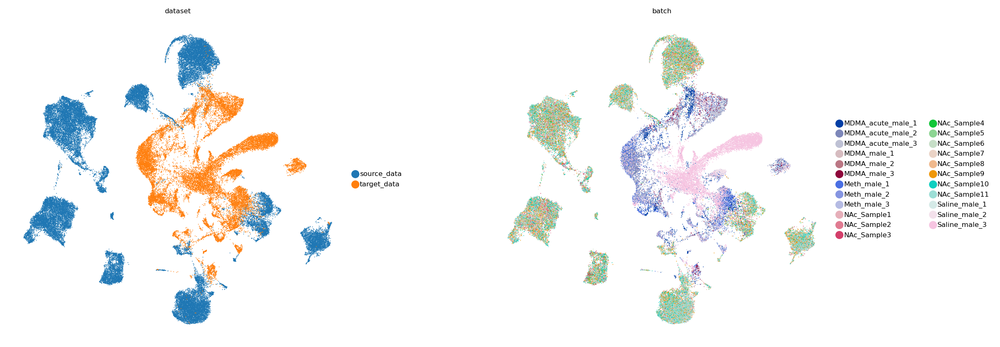

In [61]:
sc.pl.umap(
    full_latent,
    color=[
        "dataset", 'batch',
    ],
    frameon=False,
    wspace=0.3,
)
plt.show()

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


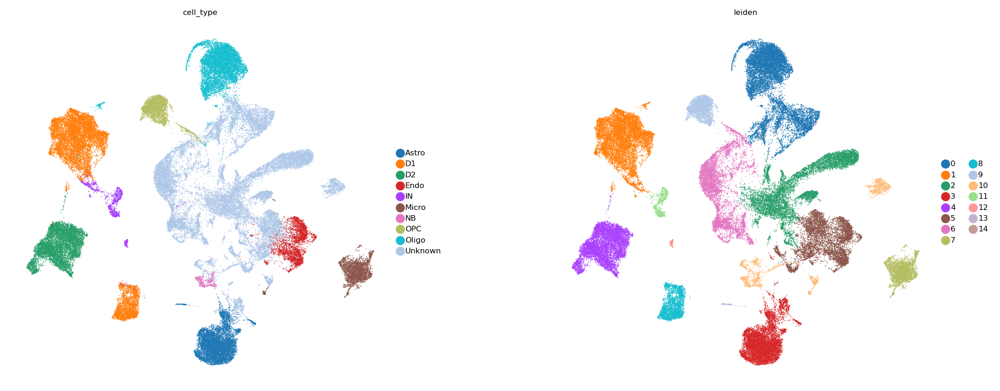

In [62]:
sc.pl.umap(
    full_latent,
    color=[
        "cell_type",'leiden',
    ],
    frameon=False,
    wspace=0.3,
)
plt.show()

In [63]:
# adata_annotated = sc.read_h5ad('preprocessing/adata-denoised-

# 

___

In [64]:
!date

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/pty.py:85: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


Sun May 19 16:57:58 PDT 2024


In [65]:
%reload_ext watermark
%watermark
%watermark --iversions

Last updated: 2024-05-19T16:57:59.283114-07:00

Python implementation: CPython
Python version       : 3.9.19
IPython version      : 8.18.1

Compiler    : GCC 12.3.0
OS          : Linux
Release     : 3.10.0-957.27.2.el7.x86_64
Machine     : x86_64
Processor   : x86_64
CPU cores   : 64
Architecture: 64bit

numpy     : 1.26.4
pandas    : 1.5.3
scarches  : 0.6.1
scez      : 0.0.5
scanpy    : 1.9.6
anndata   : 0.10.7
scvi      : 1.1.2
matplotlib: 3.6.3
torch     : 2.3.0.post100

